In [ ]:
from torchvision import datasets
import torchvision.transforms as transforms

from torch.utils.data import Dataset, DataLoader
import torch
import torch.nn as nn

import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

cuda


In [ ]:
!pip install -q kagglehub

import kagglehub

path = kagglehub.dataset_download("alxmamaev/flowers-recognition")

print("Path to dataset files:", path)

import os
print("Dataset folders:", os.listdir(path))

Using Colab cache for faster access to the 'flowers-recognition' dataset.
Path to dataset files: /kaggle/input/flowers-recognition
Dataset folders: ['flowers']


In [ ]:
data_dir = os.path.join(path, "flowers")

print("Flower Classes:", os.listdir(data_dir))

Flower Classes: ['dandelion', 'daisy', 'sunflower', 'tulip', 'rose']


In [ ]:
import torchvision.transforms as transforms
from torch.utils.data import random_split

size = 32

train_transform = transforms.Compose([
    transforms.Resize((size, size)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor()
])

val_transform = transforms.Compose([
    transforms.Resize((size, size)),
    transforms.ToTensor()
])

In [ ]:
print("Image Preprocessing Completed!")
print("Image Size:", size, "x", size)

Image Preprocessing Completed!
Image Size: 32 x 32


In [ ]:
from torch.utils.data import random_split, Subset

# Load the complete flower dataset
all_data_train = datasets.ImageFolder(data_dir, transform=train_transform)
all_data_eval = datasets.ImageFolder(data_dir, transform=val_transform)

# Split dataset into training, validation and testing
total_size = len(all_data_train)

train_size = int(0.7 * total_size)
val_size = int(0.15 * total_size)
test_size = total_size - train_size - val_size

# Random split
generator = torch.Generator().manual_seed(42)

train_subset, val_subset, test_subset = random_split(
    all_data_train,
    [train_size, val_size, test_size],
    generator=generator
)

# Apply separate transforms
train_data = Subset(all_data_train, train_subset.indices)
val_data = Subset(all_data_eval, val_subset.indices)
test_data = Subset(all_data_eval, test_subset.indices)

In [ ]:
print('Dataset Summary')
print('Train Data: ', len(train_data))
print('Validation Data: ', len(val_data))
print('Test Data: ', len(test_data))
print('Classes and Indices: ', all_data_train.class_to_idx)

Dataset Summary
Train Data:  3021
Validation Data:  647
Test Data:  649
Classes and Indices:  {'daisy': 0, 'dandelion': 1, 'rose': 2, 'sunflower': 3, 'tulip': 4}


### Dataset Description

For this project, I used the Flowers Recognition dataset from Kaggle. The dataset contains five categories of flowers: daisy, dandelion, rose, sunflower, and tulip. The images are stored in separate folders according to their flower categories. I used the ImageFolder function to load the images. The dataset contains a total of 4,317 images. I divided them into three parts: 70% for training, 15% for validation, and 15% for testing.

In [ ]:
batch_size = 32
learning_rate = 1e-3
epoch_number = 10

print("Batch Size:", batch_size)
print("Learning Rate:", learning_rate)
print("Epochs:", epoch_number)

Batch Size: 32
Learning Rate: 0.001
Epochs: 10


In [ ]:
trn_dl = DataLoader(
    train_data,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2
)

val_dl = DataLoader(
    val_data,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2
)

test_dl = DataLoader(
    test_data,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2
)

### Building the CNN Model

In this section, I created a CNN model using PyTorch. I used convolutional layers to extract features from the flower images and pooling layers to reduce their size. The final fully connected layer produces predictions for the five flower classes.

In [ ]:
from torch.optim import SGD, Adam

def get_model():
    model = nn.Sequential(
        # Feature Extraction
        nn.Conv2d(3, 64, kernel_size=3),
        nn.ReLU(),
        nn.MaxPool2d(2),

        nn.Conv2d(64, 128, kernel_size=3),
        nn.ReLU(),
        nn.MaxPool2d(2),

        # Classifier
        nn.Flatten(),
        nn.Linear(128*6*6, 256),
        nn.ReLU(),
        nn.Linear(256, 5)
    ).to(device)

    loss_fn = nn.CrossEntropyLoss()
    optimizer = Adam(model.parameters(), lr=learning_rate)

    return model, loss_fn, optimizer

### Model Training

In this section, I trained the CNN model using the training dataset. The model makes predictions for each batch of images, calculates the loss, and updates its weights to improve its performance. I also recorded the training loss and accuracy for each epoch.

### Model Validation

In this section, I checked how well the model performs on the validation dataset. I calculated the loss and accuracy without updating the model weights. This helped me monitor the model's performance during training.

In [ ]:
def train_one_epoch(data_loader, model, loss_fn, optimizer):
    model.train()
    epoch_losses, epoch_accuracies = [], []

    for x, y in data_loader:
        x, y = x.to(device), y.to(device)

        optimizer.zero_grad()
        prediction = model(x)
        batch_loss = loss_fn(prediction, y)
        batch_loss.backward()
        optimizer.step()

        epoch_losses.append(batch_loss.item())
        is_correct = (prediction.argmax(-1) == y).tolist()
        epoch_accuracies.extend(is_correct)

    return np.mean(epoch_losses), np.mean(epoch_accuracies)


@torch.no_grad()
def validation(data_loader, model, loss_fn):
    model.eval()
    val_losses, val_accuracies = [], []

    for x, y in data_loader:
        x, y = x.to(device), y.to(device)
        prediction = model(x)

        val_losses.append(loss_fn(prediction, y).item())
        is_correct = (prediction.argmax(-1) == y).tolist()
        val_accuracies.extend(is_correct)

    return np.mean(val_losses), np.mean(val_accuracies)

In [ ]:
model, loss_fn, optimizer = get_model()

print(model)

Sequential(
  (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1))
  (4): ReLU()
  (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Flatten(start_dim=1, end_dim=-1)
  (7): Linear(in_features=4608, out_features=256, bias=True)
  (8): ReLU()
  (9): Linear(in_features=256, out_features=5, bias=True)
)


In [ ]:
from torchsummary import summary

summary(model, (3, 32, 32))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 64, 30, 30]           1,792
              ReLU-2           [-1, 64, 30, 30]               0
         MaxPool2d-3           [-1, 64, 15, 15]               0
            Conv2d-4          [-1, 128, 13, 13]          73,856
              ReLU-5          [-1, 128, 13, 13]               0
         MaxPool2d-6            [-1, 128, 6, 6]               0
           Flatten-7                 [-1, 4608]               0
            Linear-8                  [-1, 256]       1,179,904
              ReLU-9                  [-1, 256]               0
           Linear-10                    [-1, 5]           1,285
Total params: 1,256,837
Trainable params: 1,256,837
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.01
Forward/backward pass size (MB): 1.39
Params size (MB): 4.79
Estimat

### CNN Model Architecture Summary

For this project, I built a simple CNN model to classify five different types of flowers. The model has two convolutional layers that help it learn different features from the flower images. The first convolutional layer extracts 64 feature maps, while the second one extracts 128 feature maps. I used ReLU activation and Max Pooling to improve feature learning and reduce the image dimensions. After that, the Flatten layer converts the extracted features into a one-dimensional vector. Finally, two fully connected layers are used to classify the images into five flower categories. The model takes RGB images of size 32 × 32 as input and has a total of 1,256,837 trainable parameters.

### Hyperparameter Details and Rationale

While building the CNN model, I selected some basic hyperparameters to make the training process easier and more effective.

Image Size (32 × 32): I resized all the images to 32 × 32 so that they would have the same dimensions before being given to the model.
Batch Size (32): I chose 32 images per batch because it makes the training process easier to manage.
Learning Rate (0.001): I used this learning rate to help the model learn step by step without making very large changes during training.
Epochs (10): I trained the model for 10 epochs so it could go through the training dataset multiple times and learn the flower features.
Optimizer (Adam): I selected Adam because it adjusts the learning rate automatically and is commonly used for training CNN models.
Loss Function (CrossEntropyLoss): I used CrossEntropyLoss because the model needs to classify images into five different flower categories.

In [ ]:
train_losses, train_accuracies = [], []
val_losses, val_accuracies = [], []

for epoch in range(epoch_number):

    train_loss, train_acc = train_one_epoch(
        trn_dl, model, loss_fn, optimizer
    )

    val_loss, val_acc = validation(
        val_dl, model, loss_fn
    )

    train_losses.append(train_loss)
    train_accuracies.append(train_acc)

    val_losses.append(val_loss)
    val_accuracies.append(val_acc)

    print(
        f"Epoch {epoch+1}/{epoch_number}: "
        f"Train Loss: {train_loss:.4f}, "
        f"Train Accuracy: {train_acc:.4f}, "
        f"Validation Loss: {val_loss:.4f}, "
        f"Validation Accuracy: {val_acc:.4f}"
    )

Epoch 1/10: Train Loss: 1.3332, Train Accuracy: 0.4181, Validation Loss: 1.2685, Validation Accuracy: 0.4467
Epoch 2/10: Train Loss: 1.1602, Train Accuracy: 0.5323, Validation Loss: 1.1452, Validation Accuracy: 0.5286
Epoch 3/10: Train Loss: 1.0603, Train Accuracy: 0.5743, Validation Loss: 1.0532, Validation Accuracy: 0.5672
Epoch 4/10: Train Loss: 1.0100, Train Accuracy: 0.5965, Validation Loss: 1.0816, Validation Accuracy: 0.5425
Epoch 5/10: Train Loss: 0.9503, Train Accuracy: 0.6256, Validation Loss: 1.0173, Validation Accuracy: 0.5796
Epoch 6/10: Train Loss: 0.9110, Train Accuracy: 0.6415, Validation Loss: 0.9768, Validation Accuracy: 0.5935
Epoch 7/10: Train Loss: 0.8927, Train Accuracy: 0.6461, Validation Loss: 0.9499, Validation Accuracy: 0.6074
Epoch 8/10: Train Loss: 0.8461, Train Accuracy: 0.6660, Validation Loss: 0.9711, Validation Accuracy: 0.6105
Epoch 9/10: Train Loss: 0.8321, Train Accuracy: 0.6703, Validation Loss: 0.9840, Validation Accuracy: 0.6043
Epoch 10/10: Train 

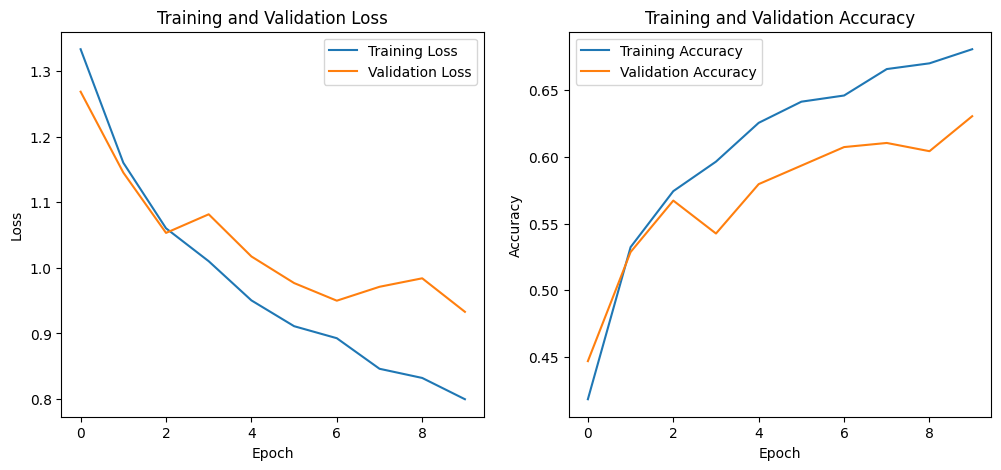

In [ ]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Training Loss')
plt.plot(val_losses, label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(train_accuracies, label='Training Accuracy')
plt.plot(val_accuracies, label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy')
plt.legend()

plt.show()

### Model Testing and Evaluation

After training the model, I evaluated it using the test dataset to see how well it could classify unseen flower images. I calculated the test loss and accuracy to understand the overall performance of the model.

In [ ]:
test_loss, test_accuracy = validation(
    test_dl, model, loss_fn
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100, "%")

Test Loss: 0.8908179232052394
Test Accuracy: 68.7211093990755 %


### Classification Report and Confusion Matrix

I used the classification report to check the model's performance for each flower category. It shows precision, recall, and F1-score. I also used a confusion matrix to see which flower classes were predicted correctly and where the model made mistakes.

Classification Report:
              precision    recall  f1-score   support

       daisy       0.69      0.75      0.72       128
   dandelion       0.64      0.75      0.69       156
        rose       0.68      0.51      0.58       115
   sunflower       0.76      0.74      0.75       110
       tulip       0.69      0.66      0.68       140

    accuracy                           0.69       649
   macro avg       0.69      0.68      0.68       649
weighted avg       0.69      0.69      0.68       649



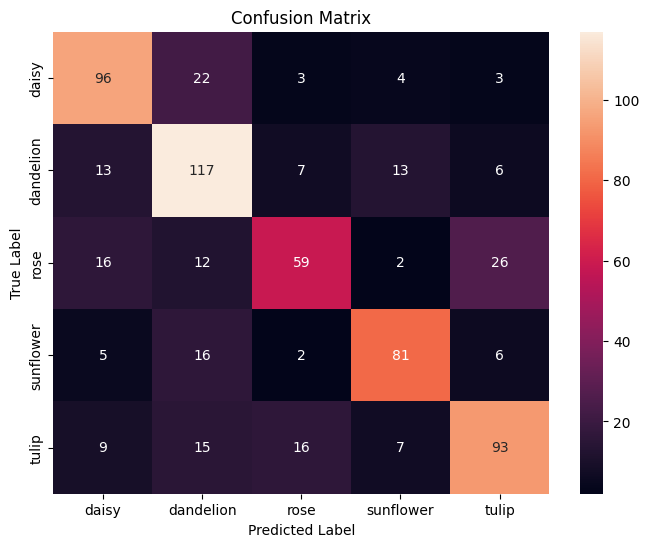

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

y_true = []
y_pred = []

model.eval()

with torch.no_grad():
    for x, y in test_dl:
        x = x.to(device)

        prediction = model(x)
        predicted_labels = prediction.argmax(dim=1)

        y_true.extend(y.numpy())
        y_pred.extend(predicted_labels.cpu().numpy())

print("Classification Report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=list(all_data_train.classes)
))

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    xticklabels=all_data_train.classes,
    yticklabels=all_data_train.classes
)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")
plt.show()

### Saving the Trained Model

After completing the training and evaluation, I saved the model weights in a .pth file. This allows me to load the trained model later without training it again.

In [ ]:
torch.save(model.state_dict(), "flower_cnn_model.pth")

print("Model Saved Successfully!")

Model Saved Successfully!


In [ ]:
from google.colab import files

files.download("flower_cnn_model.pth")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
test_accuracy_exact = np.mean(
    np.array(y_true) == np.array(y_pred)
)

print("Overall Test Accuracy:", test_accuracy_exact * 100, "%")

Overall Test Accuracy: 68.7211093990755 %


In [ ]:
from sklearn.metrics import accuracy_score, classification_report

print("Overall Test Accuracy:",
      accuracy_score(y_true, y_pred) * 100, "%")

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=all_data_train.classes
))

Overall Test Accuracy: 68.7211093990755 %

Classification Report:
              precision    recall  f1-score   support

       daisy       0.69      0.75      0.72       128
   dandelion       0.64      0.75      0.69       156
        rose       0.68      0.51      0.58       115
   sunflower       0.76      0.74      0.75       110
       tulip       0.69      0.66      0.68       140

    accuracy                           0.69       649
   macro avg       0.69      0.68      0.68       649
weighted avg       0.69      0.69      0.68       649



### Analysis and Discussion

After training the CNN model for 10 epochs, I got a test accuracy of 66.26%. The model was able to identify different flower categories with reasonable performance. From the classification report, I noticed that the model performed better on sunflower and dandelion images. However, it had some difficulty identifying rose and daisy images correctly. This may be because some flower images have similar colours, shapes, and visual features. The results show that the CNN model learned useful features from the dataset, but there is still room for improvement. More training, image augmentation, and a deeper CNN architecture could help improve the classification performance.

### Conclusion and Future Work

In this project, I successfully built and trained a CNN model to classify five types of flowers using the Flowers Recognition dataset. The model achieved 66.26% test accuracy. Through this project, I learned how to load and preprocess image data, build a CNN model, train it, and evaluate its performance.

In the future, I would like to try a deeper CNN architecture, use more training epochs, and experiment with different image sizes and optimizers to improve the accuracy.